In [ ]:
import backtrader as bt
import math
import numpy as np
import pandas as pd
import joblib
from utils import performance_metrics

In [ ]:
# --- Custom Indicator: Drift -----------------------------------------------
class Drift(bt.Indicator):
    """
    Drift indicator
    Idea base on Stochastic Derivative
    S * dt = (mu - 0.5 * sigma ** 2) * dt + sigma * Zt * dt
    drift term = mu - 0.5 * sigma ** 2
    """
    lines = ('drift',)
    params = dict(period=30)

    def __init__(self):
        self.addminperiod(self.p.period + 1)  # need past bar for log return

    def next(self):
        # log returns
        logrets = [math.log(self.data.close[i] / self.data.close[i-1]) for i in range(-self.p.period+1, 1)]
        mu = np.mean(logrets)
        var = np.var(logrets, ddof=1)  # ddof=1 for unbiased estimator
        self.lines.drift[0] = (mu - 0.5 * var) * 360

In [ ]:
# --- Strategy ---------------------------------------------------------------
class DriftStrategy(bt.Strategy):
    params = dict(
        period= 30 ,
        alloc_pct=0.1  # allocate 10% equity per trade
    )

    def __init__(self):
        self.drift = Drift(self.data, period=self.p.period)
        self.drift_ = bt.indicators.EMA(self.drift, period=self.p.period)
        
        self.equity = []
        self.dates = []

    def next(self):
        price = self.data.close[0]
        cash = self.broker.get_cash()
        size = int((cash * self.p.alloc_pct) / price)

        self.equity.append(self.broker.getvalue())
        self.dates.append(self.data.datetime.datetime(0))
        
        ma_signal = self.drift[0] > self.drift_[0]
        drift_signal = self.drift_[0] > 0
        
        if not self.position:
            # ENTRY condition
            if drift_signal and ma_signal:
                self.buy(size=size)

        else:
            # EXIT condition
            if not drift_signal or not ma_signal:
                self.close()

In [ ]:
equities = {}
metrics = {}
for ticker in tickers:
    df = format_data(datas, ticker)
    data = bt.feeds.PandasData(dataname=df)

    cerebro = bt.Cerebro()
    cerebro.addstrategy(DriftStrategy, period=30*24, alloc_pct=0.1)
    cerebro.adddata(data)
    cerebro.broker.set_cash(1_000_000)
    cerebro.broker.setcommission(commission=0.0005)
    results = cerebro.run()


    equity = results[0].equity
    dates = results[0].dates

    equity_series = pd.Series(equity, index=dates)
    
    equities[ticker] = equity_series
    metrics[ticker] = performance_metrics(equity_series, 24*365)

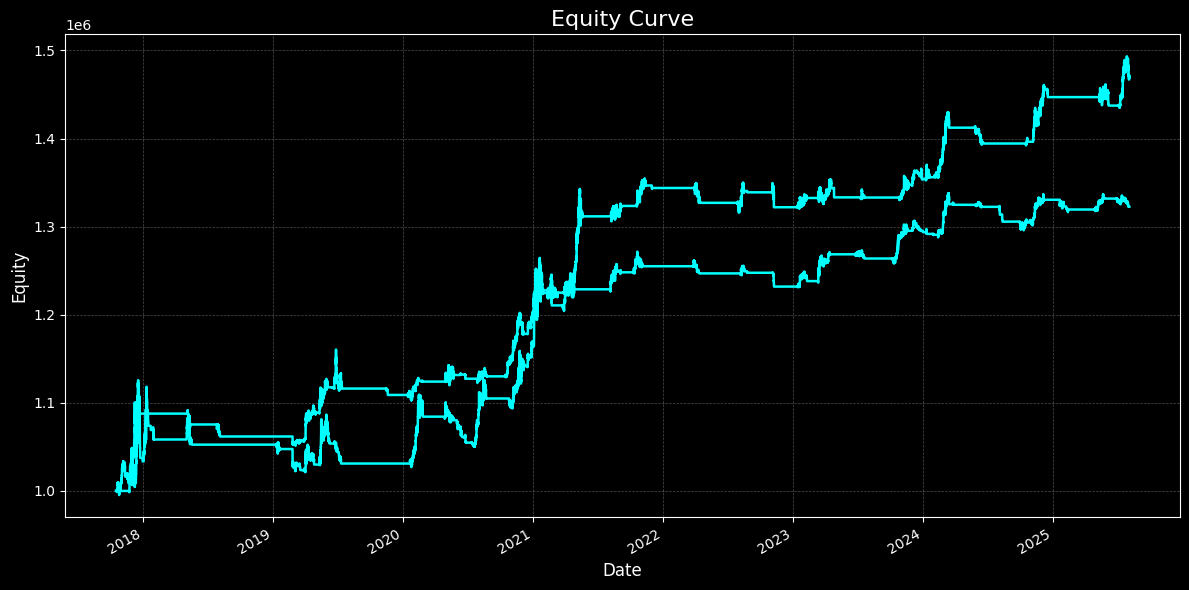

In [ ]:
import matplotlib.pyplot as plt
equities_df = pd.DataFrame(equities).dropna()

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(equities_df.index, equities_df, linewidth=1.8, color='cyan')

ax.set_title("Equity Curve", fontsize=16, color='white')
ax.set_xlabel("Date", fontsize=12, color='white')
ax.set_ylabel("Equity", fontsize=12, color='white')
ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [ ]:
# Sharpe
mean = equities_df.pct_change().mean()
std = equities_df.pct_change().std()
print(mean / std * np.sqrt(365*24))

BTCUSDT    0.945107
ETHUSDT    0.888783
dtype: float64
